In [1]:
from rdkit import Chem

In [2]:
smiles="CN1C=NC2=C1C(=O)N(C(=O)N2C)C"
molecule=Chem.MolFromSmiles(smiles)
print("molecule:",molecule)

molecule: <rdkit.Chem.rdchem.Mol object at 0x00000207F5C0E030>


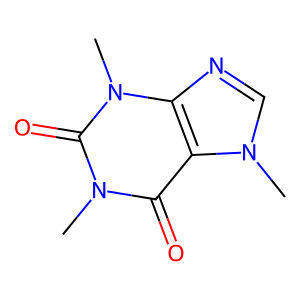

In [3]:
from rdkit.Chem import Draw
img=Draw.MolToImage(molecule)
display(img)

In [4]:
print("Number of atoms:",molecule.GetNumAtoms())
print("Number of bonds:",molecule.GetNumBonds())

Number of atoms: 14
Number of bonds: 15


In [5]:
from rdkit.Chem import rdFingerprintGenerator
from rdkit import Chem
molecule=Chem.MolFromSmiles("CN1C=NC2=C1C(=O)N(C(=O)N2C)C")
generator=rdFingerprintGenerator.GetMorganGenerator(radius=2,fpSize=128)
fingerprint=generator.GetFingerprint(molecule)
print("Fingerprint length:",len(fingerprint))
print("Fingerprint bits:",list(fingerprint))

Fingerprint length: 128
Fingerprint bits: [1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0]


In [6]:
print("Caffeine atoms:",molecule.GetNumAtoms())
print("Ethanol atoms:",molecule.GetNumAtoms())

Caffeine atoms: 14
Ethanol atoms: 14


In [85]:
from rdkit import Chem
from rdkit import Chem,DataStructs
from rdkit.Chem import rdFingerprintGenerator
caffeine=Chem.MolFromSmiles("CN1C=NC2=C1C(=O)N(C(=O)N2C)C")
ethanol=Chem.MolFromSmiles("CCO")
generator=rdFingerprintGenerator.GetMorganGenerator(radius=2,fpSize=128)
fp1=generator.GetFingerprint(caffeine)
fp2=generator.GetFingerprint(ethanol)
score=DataStructs.TanimotoSimilarity(fp1,fp2)
print("Fingerprint:",fp1.ToBitString())
print("Active bits:",list(fp1.GetOnBits()))
print(fp1.GetNumOnBits())
print(fp2.GetNumOnBits())
print("Tanimoto Similarity:",score)



Fingerprint: 11010000001000001000000000010000110010010000100000011000001000000000000000100001010000000000000000001000001001000000000011100000
Active bits: [0, 1, 3, 10, 16, 27, 32, 33, 36, 39, 44, 51, 52, 58, 74, 79, 81, 100, 106, 109, 120, 121, 122]
23
6
Tanimoto Similarity: 0.07407407407407407


In [86]:
caffeine_spectrum={195.08748:999,138.06650:336,110.07152:127,83.067789:46,69.04475:45}
max_intensity=max(caffeine_spectrum.values())
normalized_spectrum={}
for mz,intensity in caffeine_spectrum.items():
    normalized_spectrum[mz]=intensity/max_intensity

(0.0, 1.1)

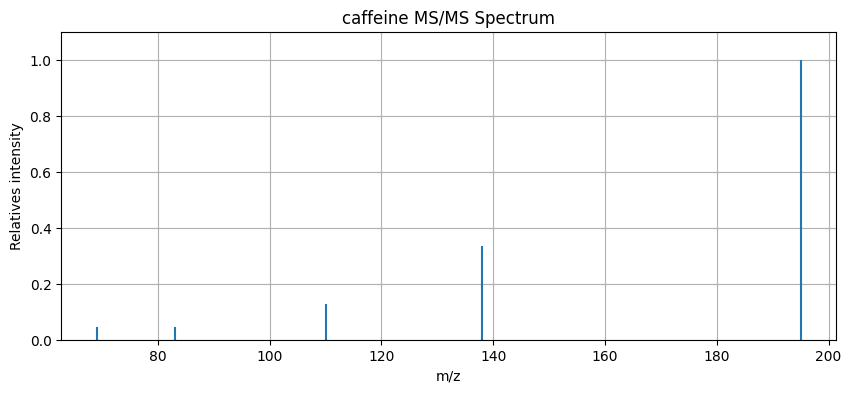

In [87]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))


for mz,intensity in normalized_spectrum.items():
    plt.vlines(mz,0,intensity)
plt.xlabel("m/z")
plt.ylabel("Relatives intensity")
plt.title("caffeine MS/MS Spectrum")
plt.grid()
plt.ylim(0,1.1)



(0.0, 1.1)

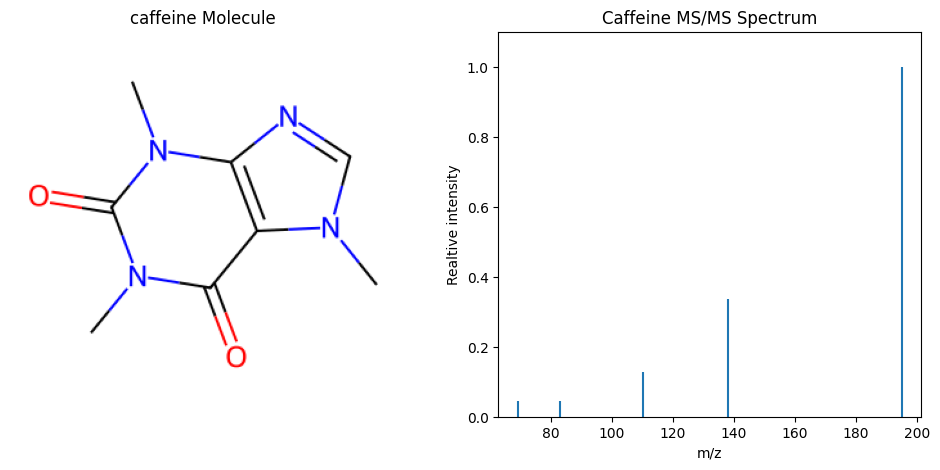

In [22]:
from rdkit.Chem import Draw
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(12,5))
axes[0].imshow(Draw.MolToImage(caffeine))
axes[0].set_title("caffeine Molecule")
axes[0].axis("off")
for mz,intensity in normalized_spectrum.items():
    axes[1].vlines(mz,0,intensity)
axes[1].set_xlabel("m/z")
axes[1].set_ylabel("Realtive intensity")
axes[1].set_title("Caffeine MS/MS Spectrum")
axes[1].set_ylim(0,1.1)



In [23]:
import pandas as pd
data={"molecule":["Caffeine"],"smiles":[Chem.MolToSmiles(caffeine)],"spectrum":[normalized_spectrum]}
df=pd.DataFrame(data)
print(df[["molecule","smiles"]])
      

   molecule                      smiles
0  Caffeine  Cn1c(=O)c2c(ncn2C)n(C)c1=O


In [24]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [25]:
for mz,intensity in sorted(normalized_spectrum.items()):
    print(f"m/z:{mz:.4f}, " 
          f"Intensity:{intensity:.3f}")

m/z:69.0447, Intensity:0.045
m/z:83.0678, Intensity:0.046
m/z:110.0715, Intensity:0.127
m/z:138.0665, Intensity:0.336
m/z:195.0875, Intensity:1.000


In [26]:
top_peaks=sorted(normalized_spectrum.items(),key=lambda x:x[1],reverse=True)[:5]
print("Top 5 Caffeine MS/MS Peaks")
print("-------------------------")
for mz,intensity in top_peaks:
    print(f"m/z={mz:.4f},Intensity={intensity:.3f}")

Top 5 Caffeine MS/MS Peaks
-------------------------
m/z=195.0875,Intensity=1.000
m/z=138.0665,Intensity=0.336
m/z=110.0715,Intensity=0.127
m/z=83.0678,Intensity=0.046
m/z=69.0447,Intensity=0.045


In [27]:
from rdkit import Chem
from rdkit.Chem import AllChem
smiles="Cn1c(=O)c2c(ncn2C)n(C)c1=O"
mol=Chem.MolFromSmiles(smiles)
if mol is None:
    print("Invalid SMILES.Check the structure.")
else:
    mol=Chem.AddHs(mol)
    result=AllChem.EmbedMolecule(mol,randomSeed=42)
    if result==0:AllChem.MMFFOptimizeMolecule(mol)
print("3D structure generated sucessfully!")



3D structure generated sucessfully!


In [28]:
import py3Dmol 
from rdkit import Chem
sdf=Chem.MolToMolBlock(mol)
viewer=py3Dmol.view(width=300,height=150)
viewer.addModel(sdf,"sdf")
viewer.setStyle({"stick":{},"sphere":{"scale":0.3}})
viewer.setBackgroundColor("white")
viewer.zoomTo()
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [29]:
from rdkit.Chem import rdMolTransforms
conf=mol.GetConformer()
print("Caffeine Bond Lengths")
print("---------------------")
for bond in mol.GetBonds():
    atom1=bond.GetBeginAtom()
    atom2=bond.GetEndAtom()
    idx1=atom1.GetIdx()
    idx2=atom2.GetIdx()
    distance=rdMolTransforms.GetBondLength(conf,idx1,idx2)
    print(f"{atom1.GetSymbol()}-{atom2.GetSymbol()}:"
          f"{distance:.3f} Angstrom")

Caffeine Bond Lengths
---------------------
C-N:1.450 Angstrom
N-C:1.398 Angstrom
C-O:1.227 Angstrom
C-C:1.421 Angstrom
C-C:1.362 Angstrom
C-N:1.362 Angstrom
N-C:1.318 Angstrom
C-N:1.370 Angstrom
N-C:1.441 Angstrom
C-N:1.374 Angstrom
N-C:1.451 Angstrom
N-C:1.395 Angstrom
C-O:1.235 Angstrom
C-N:1.411 Angstrom
N-C:1.365 Angstrom
C-H:1.093 Angstrom
C-H:1.095 Angstrom
C-H:1.095 Angstrom
C-H:1.083 Angstrom
C-H:1.093 Angstrom
C-H:1.093 Angstrom
C-H:1.093 Angstrom
C-H:1.095 Angstrom
C-H:1.095 Angstrom
C-H:1.093 Angstrom


In [30]:
print("caffeine Bond Angles")
print("---------------")
for angle in mol.GetAtoms():
    center=angle.GetIdx()
    neighbors=[atom.GetIdx() 
        for atom in angle.GetNeighbors()]
    for i in range(len(neighbors)):
        for j in range(i+1,len(neighbors)):
            a=neighbors[i]
            c=neighbors[j]
            value=rdMolTransforms.GetAngleDeg(conf,a,center,c)
            print(f"{a}-{center}-{c}:{value:.2f}degress")    
               


caffeine Bond Angles
---------------
1-0-14:112.65degress
1-0-15:108.95degress
1-0-16:108.95degress
14-0-15:108.90degress
14-0-16:108.90degress
15-0-16:108.39degress
0-1-2:118.12degress
0-1-12:116.21degress
2-1-12:125.67degress
1-2-3:124.51degress
1-2-4:112.77degress
3-2-4:122.72degress
2-4-5:123.24degress
2-4-8:131.81degress
5-4-8:104.96degress
4-5-6:111.96degress
4-5-10:121.84degress
6-5-10:126.20degress
5-6-7:104.40degress
6-7-8:111.64degress
6-7-17:125.44degress
8-7-17:122.92degress
7-8-9:126.20degress
7-8-4:107.04degress
9-8-4:126.75degress
8-9-18:108.57degress
8-9-19:108.58degress
8-9-20:109.48degress
18-9-19:110.81degress
18-9-20:109.69degress
19-9-20:109.69degress
5-10-11:120.07degress
5-10-12:119.29degress
11-10-12:120.64degress
10-11-21:109.05degress
10-11-22:109.05degress
10-11-23:111.91degress
21-11-22:109.59degress
21-11-23:108.60degress
22-11-23:108.60degress
10-12-13:121.91degress
10-12-1:117.19degress
13-12-1:120.90degress


In [31]:
from rdkit.Chem import Descriptors,rdMolDescriptors
print("Caffefine Molecular Descriptors")
print("-------------------------------")
print("Molecular weight:",Descriptors.MolWt(mol))
print("LogP:",Descriptors.MolLogP(mol))
print("TPSA:",Descriptors.TPSA(mol))
print("Number of H-bond donors:",Descriptors.NumHDonors(mol))
print("Number of H-bond acceptors:",Descriptors.NumHAcceptors(mol))
print("Number of rotatable bonds:",Descriptors.NumRotatableBonds(mol))

Caffefine Molecular Descriptors
-------------------------------
Molecular weight: 194.1940000000001
LogP: 0.061900000000000066
TPSA: 58.440000000000005
Number of H-bond donors: 0
Number of H-bond acceptors: 3
Number of rotatable bonds: 0


In [33]:
from rdkit import Chem
mol_noH=Chem.RemoveHs(mol)
print("Caffeine Carbon Atoms")
print("----------------------")
for atom in mol_noH.GetAtoms():
    if atom.GetSymbol()=="C":
        print("Atom index:",atom.GetIdx(),"| Neighbours:",atom.GetNeighbors()[0].GetSymbol(),"| Hybridization:",atom.GetHybridization(),"| Aromatic:",atom.GetIsAromatic())

Caffeine Carbon Atoms
----------------------
Atom index: 0 | Neighbours: N | Hybridization: SP3 | Aromatic: False
Atom index: 2 | Neighbours: N | Hybridization: SP2 | Aromatic: True
Atom index: 4 | Neighbours: C | Hybridization: SP2 | Aromatic: True
Atom index: 5 | Neighbours: C | Hybridization: SP2 | Aromatic: True
Atom index: 7 | Neighbours: N | Hybridization: SP2 | Aromatic: True
Atom index: 9 | Neighbours: N | Hybridization: SP3 | Aromatic: False
Atom index: 11 | Neighbours: N | Hybridization: SP3 | Aromatic: False
Atom index: 12 | Neighbours: N | Hybridization: SP2 | Aromatic: True


In [34]:
import pandas as pd
carbon_data=[]
for atom in mol_noH.GetAtoms():
    if atom.GetSymbol()=="C":carbon_data.append({"Atom_Index":atom.GetIdx(),"Hybridization":str(atom.GetHybridization()),"Aromatic":atom.GetIsAromatic(),"Degree":atom.GetDegree(),"Formal_Charge":atom.GetFormalCharge()})
carbon_df=pd.DataFrame(carbon_data)
carbon_df

,Atom_Index,Hybridization,Aromatic,Degree,Formal_Charge
0,0,SP3,False,1,0
1,2,SP2,True,3,0
2,4,SP2,True,3,0
3,5,SP2,True,3,0
4,7,SP2,True,2,0
5,9,SP3,False,1,0
6,11,SP3,False,1,0
7,12,SP2,True,3,0


In [35]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
feature_columns=["Aromatic","Degree","Formal_Charge"]
X=carbon_df[feature_columns].copy()
X["Aromatic"]=X["Aromatic"].astype(int)
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
print("Input features:")
print(X)


Input features:
   Aromatic  Degree  Formal_Charge
0         0       1              0
1         1       3              0
2         1       3              0
3         1       3              0
4         1       2              0
5         0       1              0
6         0       1              0
7         1       3              0


In [36]:
y=None
print("Number of carbon atoms:",len(carbon_df))
print("Reference shifts loaded:",y is not None)

Number of carbon atoms: 8
Reference shifts loaded: False


In [40]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics  import mean_absolute_error
if y is None:
    print("Load the experimental NMR shifts first.")
else:
    model=RandomForestRegressor(n_estimators=100,random_state=42)
    model.fit(X_scaled,y)
    predictions=model.predict(X_scaled)
    print("Reference shifts:",y)
    print("Predicted shifts:",predictions)

Load the experimental NMR shifts first.


In [42]:
print("Target y:",y)
print("X shape:",X.shape)
print("Model exists:","model" in globals())
if "model" in globals():
    print("Model:",model)
    print("Predictions:",model.predict(X_scaled))

Target y: None
X shape: (8, 3)
Model exists: False


In [43]:
import numpy as np
y=np.array([151.00,148.07,106.16,154.50,142.77,27.45,29.34,33.11])
print("Number of reference shifts:",len(y))
print("Number of carbon atoms:",len(carbon_df))


Number of reference shifts: 8
Number of carbon atoms: 8


In [44]:
print(carbon_df)

   Atom_Index Hybridization  Aromatic  Degree  Formal_Charge
0           0           SP3     False       1              0
1           2           SP2      True       3              0
2           4           SP2      True       3              0
3           5           SP2      True       3              0
4           7           SP2      True       2              0
5           9           SP3     False       1              0
6          11           SP3     False       1              0
7          12           SP2      True       3              0


In [45]:
from rdkit import Chem
print("Carbon atom environments")
print("------------------------")
for atom in mol_noH.GetAtoms():
    if atom.GetSymbol()=="C":neighbors=[]
for neighbor in atom.GetNeighbors():
    bond=mol_noH.GetBondBetweenAtoms(atom.GetIdx(),neighbor.GetIdx())
    neighbors.append(f"{neighbor.GetSymbol()}"f"(atom{neighbor.GetIdx()},"f"bond{bond.GetBondType()})")
    print(f"Carbon{atom.GetIdx()}:"+",".join(neighbors))

Carbon atom environments
------------------------
Carbon13:C(atom12,bondDOUBLE)


In [46]:
for atom in mol_noH.GetAtoms():
    if atom.GetSymbol()=="C":
        print(atom.GetIdx(),atom.GetIsAromatic(),atom.GetHybridization(),[(n.GetIdx(),mol_noH.GetBondBetweenAtoms(atom.GetIdx(),n.GetIdx()).GetBondType())
        for n in atom.GetNeighbors()])

0 False SP3 [(1, rdkit.Chem.rdchem.BondType.SINGLE)]
2 True SP2 [(1, rdkit.Chem.rdchem.BondType.AROMATIC), (3, rdkit.Chem.rdchem.BondType.DOUBLE), (4, rdkit.Chem.rdchem.BondType.AROMATIC)]
4 True SP2 [(2, rdkit.Chem.rdchem.BondType.AROMATIC), (5, rdkit.Chem.rdchem.BondType.AROMATIC), (8, rdkit.Chem.rdchem.BondType.AROMATIC)]
5 True SP2 [(4, rdkit.Chem.rdchem.BondType.AROMATIC), (6, rdkit.Chem.rdchem.BondType.AROMATIC), (10, rdkit.Chem.rdchem.BondType.AROMATIC)]
7 True SP2 [(6, rdkit.Chem.rdchem.BondType.AROMATIC), (8, rdkit.Chem.rdchem.BondType.AROMATIC)]
9 False SP3 [(8, rdkit.Chem.rdchem.BondType.SINGLE)]
11 False SP3 [(10, rdkit.Chem.rdchem.BondType.SINGLE)]
12 True SP2 [(10, rdkit.Chem.rdchem.BondType.AROMATIC), (13, rdkit.Chem.rdchem.BondType.DOUBLE), (1, rdkit.Chem.rdchem.BondType.AROMATIC)]


In [47]:
for atom in mol_noH.GetAtoms():
    if atom.GetSymbol()=="C":
        print("Carbon:",atom.GetIdx(),"| Neighbors:",[(n.GetSymbol(),n.GetIdx())
        for n in atom.GetNeighbors()])

Carbon: 0 | Neighbors: [('N', 1)]
Carbon: 2 | Neighbors: [('N', 1), ('O', 3), ('C', 4)]
Carbon: 4 | Neighbors: [('C', 2), ('C', 5), ('N', 8)]
Carbon: 5 | Neighbors: [('C', 4), ('N', 6), ('N', 10)]
Carbon: 7 | Neighbors: [('N', 6), ('N', 8)]
Carbon: 9 | Neighbors: [('N', 8)]
Carbon: 11 | Neighbors: [('N', 10)]
Carbon: 12 | Neighbors: [('N', 10), ('O', 13), ('N', 1)]


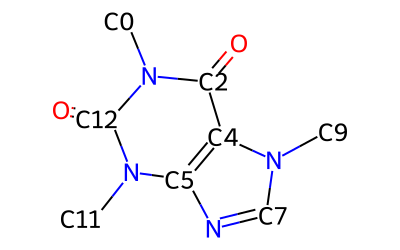

In [48]:
from rdkit import Chem
from rdkit.Chem import Draw
mol_label=Chem.Mol(mol_noH)
for atom in mol_label.GetAtoms():
    if atom.GetSymbol()=="C":atom.SetProp("atomLabel",f"C{atom.GetIdx()}")
img=Draw.MolToImage(mol_label,size=(400,250),kekulize=True)
display(img)

In [51]:
print(X.shape)

(8, 3)


In [52]:
print("Row | RDKit atom index")
for row,atom_index in enumerate(carbon_df["Atom_Index"]):
    print(row,"|",atom_index)

Row | RDKit atom index
0 | 0
1 | 2
2 | 4
3 | 5
4 | 7
5 | 9
6 | 11
7 | 12


In [53]:
print("X shape:",X.shape)
print("Carbon indices:",carbon_df["Atom_Index"].tolist())

X shape: (8, 3)
Carbon indices: [0, 2, 4, 5, 7, 9, 11, 12]


In [54]:
import numpy as np
import pandas as pd
synthetic_shifts={0:28.0,2:151.0,4:108.0,5:142.0,7:155.0,9:29.0,11:330,12:154.0}
y=np.array([synthetic_shifts[idx]
   for idx in carbon_df["Atom_Index"]])
print("Synthetic target values:",y)
print("Number of target:",len(y))
print("Feature mateix shape:",X_scaled.shape)

Synthetic target values: [ 28. 151. 108. 142. 155.  29. 330. 154.]
Number of target: 8
Feature mateix shape: (8, 3)


In [55]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd
model=RandomForestRegressor(n_estimators=100,max_depth=4,random_state=42)
model.fit(X_scaled,y)
print("Random Forest training completed!")
predictions=model.predict(X_scaled)
results=pd.DataFrame({"Atom_Index":carbon_df["Atom_Index"].values,"Synthetic_Actual_ppm":y,"Predicted_ppm":predictions})
results["Absolute_Error"]=abs(results["Synthetic_Actual_ppm"]-results["Predicted_ppm"])


Random Forest training completed!


In [56]:
mae=mean_absolute_error(y,predictions)
print("training MAE:",round(mae,2),"ppm")

training MAE: 56.96 ppm


In [57]:
results["Error"]=(results["Predicted_ppm"]-results["Synthetic_Actual_ppm"])
print(results.round(2).to_string(index=False))
print("\nMean Absolute Error:",round(mae,2),"ppm")

 Atom_Index  Synthetic_Actual_ppm  Predicted_ppm  Absolute_Error   Error
          0                  28.0         117.31           89.31   89.31
          2                 151.0         139.42           11.58  -11.58
          4                 108.0         139.42           31.42   31.42
          5                 142.0         139.42            2.58   -2.58
          7                 155.0         149.77            5.23   -5.23
          9                  29.0         117.31           88.31   88.31
         11                 330.0         117.31          212.69 -212.69
         12                 154.0         139.42           14.58  -14.58

Mean Absolute Error: 56.96 ppm


In [58]:
import pandas as pd
reference_df=pd.DataFrame({"Atom_Index":[0,2,4,5,7,9,11,12],"Experimental_Shifts_ppm":[None]*8})
display(reference_df)

,Atom_Index,Experimental_Shifts_ppm
0,0,None
1,2,None
2,4,None
3,5,None
4,7,None
5,9,None
6,11,None
7,12,None


In [59]:
print(reference_df)

   Atom_Index Experimental_Shifts_ppm
0           0                    None
1           2                    None
2           4                    None
3           5                    None
4           7                    None
5           9                    None
6          11                    None
7          12                    None


In [60]:
print(reference_df.dtypes)

Atom_Index                  int64
Experimental_Shifts_ppm    object
dtype: object


In [61]:
experimental_shifts={0:27.4,2:150.9,4:148.0,5:106.5,7:142.7,9:33.1,11:29.3,12:154.4}
reference_df["experimental_shifts_ppm"]=(reference_df["Atom_Index"].map(experimental_shifts))


In [62]:
reference_df["Experimental_Shifts_ppm"]=(reference_df["Atom_Index"].map(experimental_shifts))
print(reference_df)

   Atom_Index  Experimental_Shifts_ppm  experimental_shifts_ppm
0           0                     27.4                     27.4
1           2                    150.9                    150.9
2           4                    148.0                    148.0
3           5                    106.5                    106.5
4           7                    142.7                    142.7
5           9                     33.1                     33.1
6          11                     29.3                     29.3
7          12                    154.4                    154.4


In [63]:
print(reference_df.isnull().sum())
print(reference_df)

Atom_Index                 0
Experimental_Shifts_ppm    0
experimental_shifts_ppm    0
dtype: int64
   Atom_Index  Experimental_Shifts_ppm  experimental_shifts_ppm
0           0                     27.4                     27.4
1           2                    150.9                    150.9
2           4                    148.0                    148.0
3           5                    106.5                    106.5
4           7                    142.7                    142.7
5           9                     33.1                     33.1
6          11                     29.3                     29.3
7          12                    154.4                    154.4


In [64]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
training_df=carbon_df.merge(reference_df,on="Atom_Index")
X=training_df[["Aromatic","Degree","Formal_Charge"]].astype(float)
y=training_df["Experimental_Shifts_ppm"].astype(float)
print("X shape:",X.shape)
print("y shape:",y.shape)
print("Missing values:",y.isna().sum())

X shape: (8, 3)
y shape: (8,)
Missing values: 0


In [65]:
model=RandomForestRegressor(n_estimators=100,random_state=42)
model.fit(X,y)
predictions=model.predict(X)
mae=mean_absolute_error(y,predictions)
print("Model trainined successfully!")
print("Training MAE:",round(mae,2),"ppm")

Model trainined successfully!
Training MAE: 11.53 ppm


In [66]:
results=training_df[["Atom_Index"]].copy()
results["Experimental_ppm"]=y.values
results["Predictions_ppm"]=predictions
results["Absolute_Error"]=np.abs(y.values-predictions)
display(results.round(2))

,Atom_Index,Experimental_ppm,Predictions_ppm,Absolute_Error
0,0,27.4,32.26,4.86
1,2,150.9,140.71,10.19
2,4,148.0,140.71,7.29
3,5,106.5,140.71,34.21
4,7,142.7,124.46,18.24
5,9,33.1,32.26,0.84
6,11,29.3,32.26,2.96
7,12,154.4,140.71,13.69


In [67]:
print("Training MAE:",round(mae,2),"ppm")
print(results.round(2))

Training MAE: 11.53 ppm
   Atom_Index  Experimental_ppm  Predictions_ppm  Absolute_Error
0           0              27.4            32.26            4.86
1           2             150.9           140.71           10.19
2           4             148.0           140.71            7.29
3           5             106.5           140.71           34.21
4           7             142.7           124.46           18.24
5           9              33.1            32.26            0.84
6          11              29.3            32.26            2.96
7          12             154.4           140.71           13.69


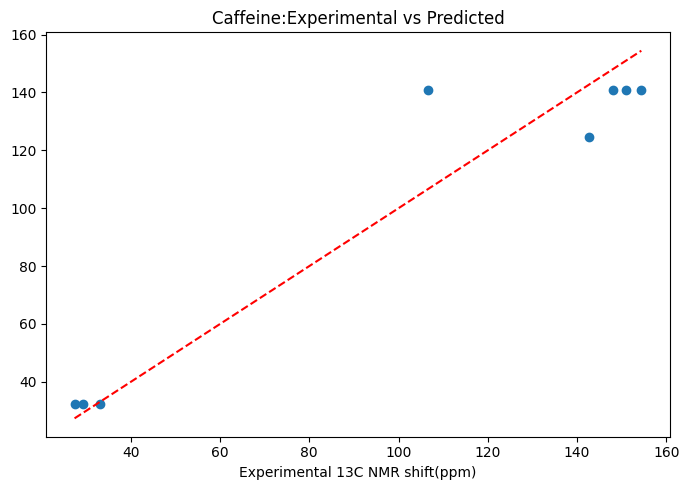

In [68]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7,5))
plt.scatter(y,predictions)
plt.plot([min(y),max(y)],[min(y),max(y)],"r--")
plt.xlabel("Experimental 13C NMR shift(ppm)")
plt.title("Caffeine:Experimental vs Predicted")
plt.tight_layout()
plt.show()

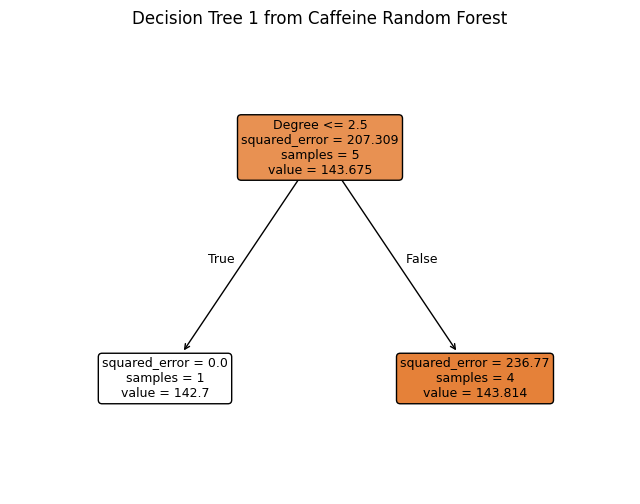

In [69]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
one_tree=model.estimators_[0]
plt.figure(figsize=(8,6))
plot_tree(one_tree,feature_names=["Aromatic","Degree","Foraml_Charge"],filled=True,rounded=True,fontsize=9)
plt.title("Decision Tree 1 from Caffeine Random Forest")
plt.show()

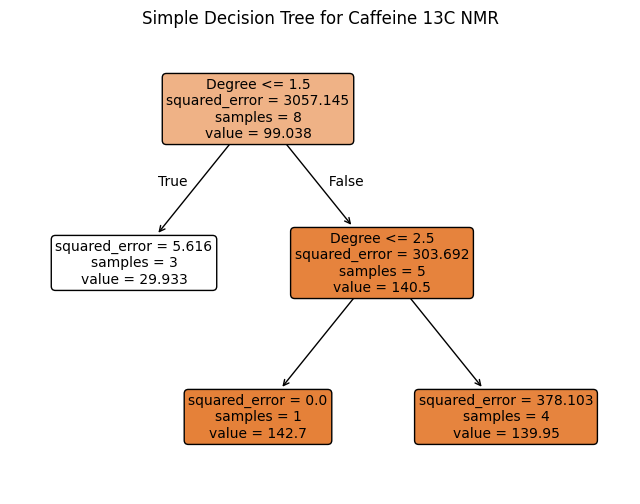

In [70]:
from sklearn.tree import DecisionTreeRegressor,plot_tree
import matplotlib.pyplot as plt
simple_tree=DecisionTreeRegressor(max_depth=3,random_state=42)
simple_tree.fit(X,y)
plt.figure(figsize=(8,6))
plot_tree(simple_tree,feature_names=["Aromatic","Degree","Foraml_Charge"],filled=True,rounded=True,fontsize=10)
plt.title("Simple Decision Tree for Caffeine 13C NMR")
plt.show()

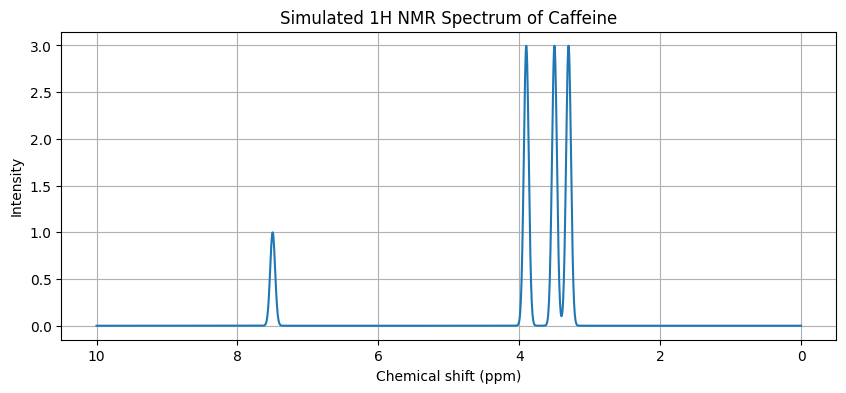

In [71]:
import numpy as np
import matplotlib.pyplot as plt

# Chemical shift axis
ppm = np.linspace(10, 0, 2000)

# Approximate caffeine proton signals
peak_positions =  [3.3, 3.5, 3.9, 7.5]
peak_heights = [3, 3, 3, 1]

# Create spectrum
spectrum = np.zeros_like(ppm)

for pos, height in zip(peak_positions, peak_heights):

    width = 0.035

    signal = height * np.exp(
        -0.5 * ((ppm - pos) / width)**2
    )

    spectrum += signal

# Plot 1D spectrum
plt.figure(figsize=(10, 4))
plt.plot(ppm, spectrum)

plt.xlabel("Chemical shift (ppm)")
plt.ylabel("Intensity")
plt.title("Simulated 1H NMR Spectrum of Caffeine")

plt.gca().invert_xaxis()
plt.grid()
plt.show()

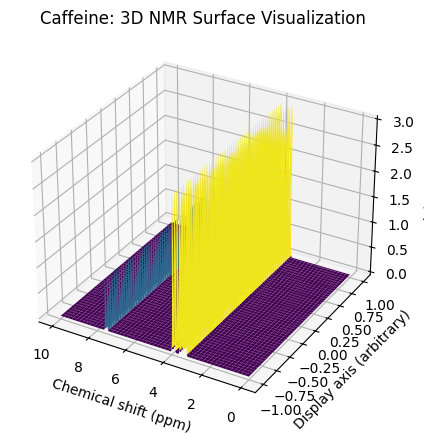

In [89]:
from mpl_toolkits.mplot3d import Axes3D

# X axis: chemical shift
# Y axis: artificial display dimension
x = ppm
y = np.linspace(-1, 1, 100)

X, Y = np.meshgrid(x, y)

# Extend the 1D spectrum across Y
# The small Gaussian factor gives the peaks
# a ridge-like shape.
Z = np.tile(spectrum, (len(y), 1))

# 3D plot
fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    linewidth=0,
    antialiased=True
)

ax.set_xlabel("Chemical shift (ppm)")
ax.set_ylabel("Display axis (arbitrary)")
ax.set_zlabel("Intensity")

ax.set_title("Caffeine: 3D NMR Surface Visualization")

ax.invert_xaxis()

plt.show()